# UAE JobShield — NLP Recruitment Scam Detection

**Student:** Aditi Pateriya  
**Student ID:** 1672587

## Notebook purpose
This notebook trains and evaluates a three-class recruitment-message screening prototype:
- **Fraudulent**
- **Suspicious**
- **Legitimate**

It compares a word-level TF-IDF baseline with a hybrid word- and character-level TF-IDF model using Logistic Regression. It also evaluates duplicate-aware generalisation, inspects errors, applies transparent UAE-relevant warning rules, and launches an optional Gradio demo.

> **Important scope note:** The dataset is a public job-posting dataset and is not a representative UAE-only dataset. UAE-specific warning guidance is used to contextualise the prototype, not to claim that the training data represents the UAE labour market. This is a screening aid, not an official fraud verdict or employer-verification service.

## 1. Install and import dependencies

In [1]:
%pip -q install datasets pandas numpy scikit-learn matplotlib seaborn joblib gradio

In [2]:
import re
import json
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from datasets import load_dataset
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_fscore_support
)
from sklearn.pipeline import FeatureUnion
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_colwidth", 140)

print("Python notebook started:", datetime.now(timezone.utc).isoformat())
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python notebook started: 2026-10-31T11:23:41.497550+00:00
pandas: 2.2.3
scikit-learn: 1.6.1


## 2. Load the dataset

In [3]:
DATASET_ID = "agnialf/Internship-Job-Scam-Dataset"
dataset = load_dataset(DATASET_ID)
print(dataset)
print("Available splits:", list(dataset.keys()))

data = dataset["train"].to_pandas()
print("Dataset shape:", data.shape)
display(data.head(5))
print("\nColumns:", data.columns.tolist())

README.md:   0%|          | 0.00/3.50k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


internship_job_scam_dataset.csv:   0%|          | 0.00/2.34M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/900 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'source_job_id', 'title', 'location', 'text', 'label', 'risk_level', 'red_flags', 'source_dataset', 'source_type', 'original_fraudulent', 'internship_related'],
        num_rows: 900
    })
})
Available splits: ['train']
Dataset shape: (900, 12)


,id,source_job_id,title,location,text,label,risk_level,red_flags,source_dataset,source_type,original_fraudulent,internship_related
0,1,6111,Data Entry,"US, NY, ACRA","Title: Data Entry\nLocation: US, NY, ACRA\nDescription: Data EntryThe purpose of this position is to complete study related case report ...",fraudulent,high,missing_company_profile;no_company_logo;no_screening_questions,EMSCAD_real_fake_job_postings,processed_public_dataset,1,True
1,2,4670,Associate Business Development,"DK, , Work from home","Title: Associate Business Development\nLocation: DK, , Work from home\nDescription: Want to build a career in IT? Free training in excha...",suspicious,medium,missing_company_profile;missing_requirements;no_company_logo;no_screening_questions,EMSCAD_real_fake_job_postings,processed_public_dataset,0,True
2,3,5689,Call Center Representative,"US, TX, HOUSTON","Title: Call Center Representative\nLocation: US, TX, HOUSTON\nSalary Range: 1000-2000\nDescription: Duties and Responsibilities:Answer C...",fraudulent,high,missing_company_profile;no_company_logo;no_screening_questions,EMSCAD_real_fake_job_postings,processed_public_dataset,1,True
3,4,10319,Customer support(Junior position),"GR, I, Athens","Title: Customer support(Junior position)\nLocation: GR, I, Athens\nSalary Range: 1000-1100\nDescription: We need a person that has lots ...",legitimate,low,missing_company_profile;no_company_logo;no_screening_questions,EMSCAD_real_fake_job_postings,processed_public_dataset,0,True
4,5,2368,Software Engineer | Forecasting & Optimization,"US, CA, San Mateo","Title: Software Engineer | Forecasting & Optimization\nLocation: US, CA, San Mateo\nDepartment: Engineering\nCompany Profile: Aptitude S...",fraudulent,high,none,EMSCAD_real_fake_job_postings,processed_public_dataset,1,False



Columns: ['id', 'source_job_id', 'title', 'location', 'text', 'label', 'risk_level', 'red_flags', 'source_dataset', 'source_type', 'original_fraudulent', 'internship_related']


## 3. Data inspection and quality checks

In [4]:
print("Data types:")
display(data.dtypes.to_frame("dtype"))

print("Missing values:")
missing_summary = data.isna().sum().sort_values(ascending=False).to_frame("missing_count")
display(missing_summary)

print("Duplicate text rows:", data["text"].fillna("").duplicated().sum())
print("Unique labels:", data["label"].value_counts(dropna=False).to_dict())
print("Unique risk levels:", data["risk_level"].value_counts(dropna=False).to_dict())

# Remove rows without usable text or labels; keep one copy of exact duplicate text
# for the primary modelling experiment to avoid identical text appearing twice.
data = data.dropna(subset=["text", "label"]).copy()
data["text"] = data["text"].astype(str).str.strip()
data = data[data["text"].ne("")].copy()
data["label"] = data["label"].astype(str).str.strip().str.lower()
data = data.drop_duplicates(subset=["text"], keep="first").reset_index(drop=True)

print("Shape after dropping missing/blank text and exact duplicate text:", data.shape)
display(data[["title", "location", "label", "risk_level", "text"]].head(8))

Data types:


,dtype
id,int64
source_job_id,object
title,object
location,object
text,object
label,object
risk_level,object
red_flags,object
source_dataset,object
source_type,object


Missing values:


,missing_count
location,14
id,0
source_job_id,0
title,0
text,0
label,0
risk_level,0
red_flags,0
source_dataset,0
source_type,0


Duplicate text rows: 6
Unique labels: {'fraudulent': 300, 'suspicious': 300, 'legitimate': 300}
Unique risk levels: {'high': 300, 'medium': 300, 'low': 300}
Shape after dropping missing/blank text and exact duplicate text: (894, 12)


,title,location,label,risk_level,text
0,Data Entry,"US, NY, ACRA",fraudulent,high,"Title: Data Entry\nLocation: US, NY, ACRA\nDescription: Data EntryThe purpose of this position is to complete study related case report ..."
1,Associate Business Development,"DK, , Work from home",suspicious,medium,"Title: Associate Business Development\nLocation: DK, , Work from home\nDescription: Want to build a career in IT? Free training in excha..."
2,Call Center Representative,"US, TX, HOUSTON",fraudulent,high,"Title: Call Center Representative\nLocation: US, TX, HOUSTON\nSalary Range: 1000-2000\nDescription: Duties and Responsibilities:Answer C..."
3,Customer support(Junior position),"GR, I, Athens",legitimate,low,"Title: Customer support(Junior position)\nLocation: GR, I, Athens\nSalary Range: 1000-1100\nDescription: We need a person that has lots ..."
4,Software Engineer | Forecasting & Optimization,"US, CA, San Mateo",fraudulent,high,"Title: Software Engineer | Forecasting & Optimization\nLocation: US, CA, San Mateo\nDepartment: Engineering\nCompany Profile: Aptitude S..."
5,Entry Level Accounting Specialist,"US, FL, Fort Lauderdale",suspicious,medium,"Title: Entry Level Accounting Specialist\nLocation: US, FL, Fort Lauderdale\nDescription: We have an immediate opening for an Accounting..."
6,Payroll Data Coordinator Positions - Earn $100-$200 Daily,"US, ME, Abbot",fraudulent,high,"Title: Payroll Data Coordinator Positions - Earn $100-$200 Daily\nLocation: US, ME, Abbot\nDescription: We are a full-service marketing ..."
7,Data Entry Admin/Clerical Positions - Work From Home,"US, AK, Anchorage",fraudulent,high,"Title: Data Entry Admin/Clerical Positions - Work From Home\nLocation: US, AK, Anchorage\nDescription: ACCEPTING ONLINE APPLICATIONS ONL..."


## 4. Exploratory data analysis

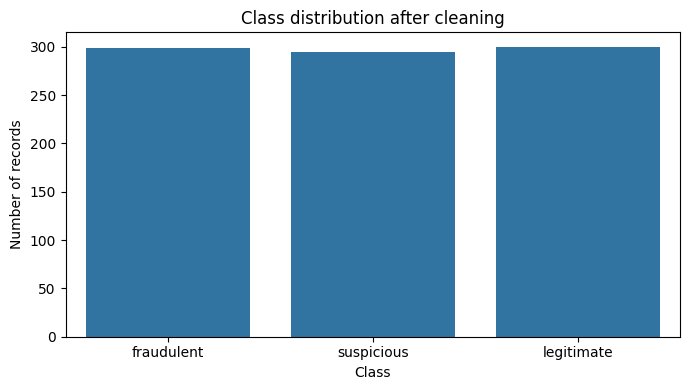

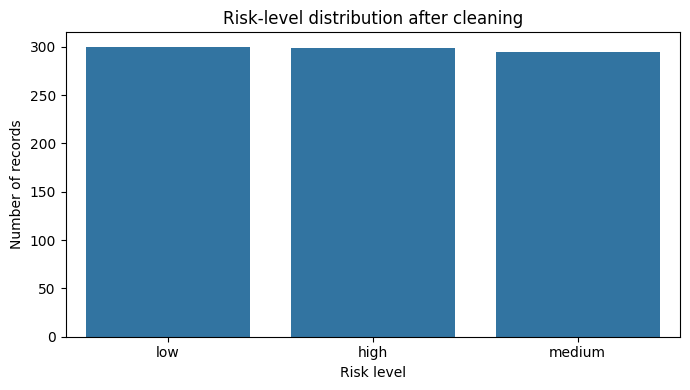

Class proportions:


,percentage
label,
legitimate,33.56
fraudulent,33.45
suspicious,33.00


In [5]:
label_counts = data["label"].value_counts().reindex(["fraudulent", "suspicious", "legitimate"])
plt.figure(figsize=(7, 4))
sns.barplot(x=label_counts.index, y=label_counts.values)
plt.title("Class distribution after cleaning")
plt.xlabel("Class")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

risk_counts = data["risk_level"].value_counts()
plt.figure(figsize=(7, 4))
sns.barplot(x=risk_counts.index, y=risk_counts.values)
plt.title("Risk-level distribution after cleaning")
plt.xlabel("Risk level")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

print("Class proportions:")
display((data["label"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

## 5. Prepare text and labels

The primary modelling input is the `text` field. TF-IDF converts text into sparse numerical features based on word and character patterns. The model predicts one of the three dataset labels.

In [6]:
X = data["text"].astype(str)
y = data["label"].astype(str)

print("Number of examples:", len(data))
print("Classes:", sorted(y.unique()))
print("Text length summary:")
display(X.str.split().str.len().describe().to_frame("word_count"))

Number of examples: 894
Classes: ['fraudulent', 'legitimate', 'suspicious']
Text length summary:


,word_count
count,894.000000
mean,331.770694
std,217.057720
min,6.000000
25%,164.250000
50%,302.000000
75%,441.750000
max,1356.000000


## 6. Primary experiment: stratified random train/test split

The first experiment uses an 80/20 stratified split. Stratification aims to preserve the class proportions in the training and test sets. This is the directly comparable primary experiment for the two models.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training examples:", len(X_train))
print("Test examples:", len(X_test))
print("\nTraining class distribution:")
display(y_train.value_counts().to_frame("count"))
print("Test class distribution:")
display(y_test.value_counts().to_frame("count"))

Training examples: 715
Test examples: 179

Training class distribution:


,count
label,
legitimate,240
fraudulent,239
suspicious,236


Test class distribution:


,count
label,
fraudulent,60
legitimate,60
suspicious,59


## 7. Baseline model — word-level TF-IDF + Logistic Regression

Baseline accuracy: 0.8045 (80.45%)

Baseline classification report:
              precision    recall  f1-score   support

  fraudulent       0.88      0.87      0.87        60
  legitimate       0.73      0.80      0.76        60
  suspicious       0.81      0.75      0.78        59

    accuracy                           0.80       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.80      0.81       179



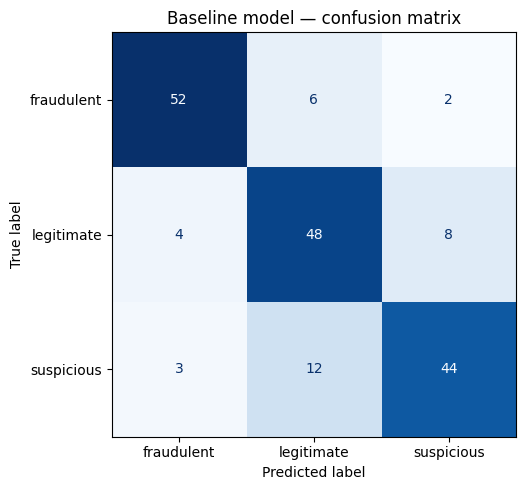

In [8]:
baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        max_features=20000,
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
print(f"Baseline accuracy: {baseline_accuracy:.4f} ({baseline_accuracy*100:.2f}%)")
print("\nBaseline classification report:")
print(classification_report(y_test, baseline_predictions, zero_division=0))

baseline_labels = sorted(y.unique())
baseline_cm = confusion_matrix(y_test, baseline_predictions, labels=baseline_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=baseline_cm, display_labels=baseline_labels)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Baseline model — confusion matrix")
plt.tight_layout()
plt.show()

## 8. Improved model — word + character TF-IDF

The improved model combines:
- **Word n-grams (1–2):** capture words and short phrases.
- **Character n-grams (3–5):** can capture fragments, spelling variations and unusual word forms.

Both feature sets are passed to Logistic Regression. This is still a classical machine-learning NLP model; it is not a fine-tuned LLM or a dense semantic embedding model.

Improved accuracy: 0.8324 (83.24%)

Improved classification report:
              precision    recall  f1-score   support

  fraudulent       0.89      0.92      0.90        60
  legitimate       0.79      0.82      0.80        60
  suspicious       0.82      0.76      0.79        59

    accuracy                           0.83       179
   macro avg       0.83      0.83      0.83       179
weighted avg       0.83      0.83      0.83       179



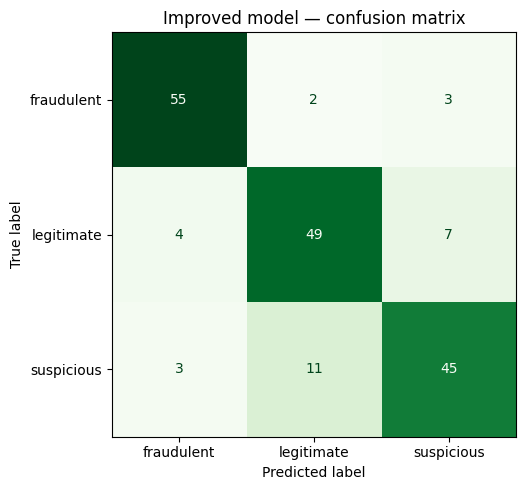

In [9]:
improved_features = FeatureUnion([
    ("word_tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        max_features=20000,
        min_df=2,
        sublinear_tf=True
    )),
    ("char_tfidf", TfidfVectorizer(
        lowercase=True,
        analyzer="char_wb",
        ngram_range=(3, 5),
        max_features=20000,
        min_df=2,
        sublinear_tf=True
    ))
])

improved_model = Pipeline([
    ("features", improved_features),
    ("classifier", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

improved_model.fit(X_train, y_train)
improved_predictions = improved_model.predict(X_test)
improved_accuracy = accuracy_score(y_test, improved_predictions)

print(f"Improved accuracy: {improved_accuracy:.4f} ({improved_accuracy*100:.2f}%)")
print("\nImproved classification report:")
print(classification_report(y_test, improved_predictions, zero_division=0))

labels = sorted(y.unique())
improved_cm = confusion_matrix(y_test, improved_predictions, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=improved_cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Greens", values_format="d", colorbar=False)
plt.title("Improved model — confusion matrix")
plt.tight_layout()
plt.show()

## 9. Compare baseline and improved model

,Accuracy,Macro precision,Macro recall,Macro F1
Model,,,,
Baseline: word TF-IDF,0.8045,0.8078,0.8041,0.8049
Improved: word + character TF-IDF,0.8324,0.8319,0.8320,0.8315


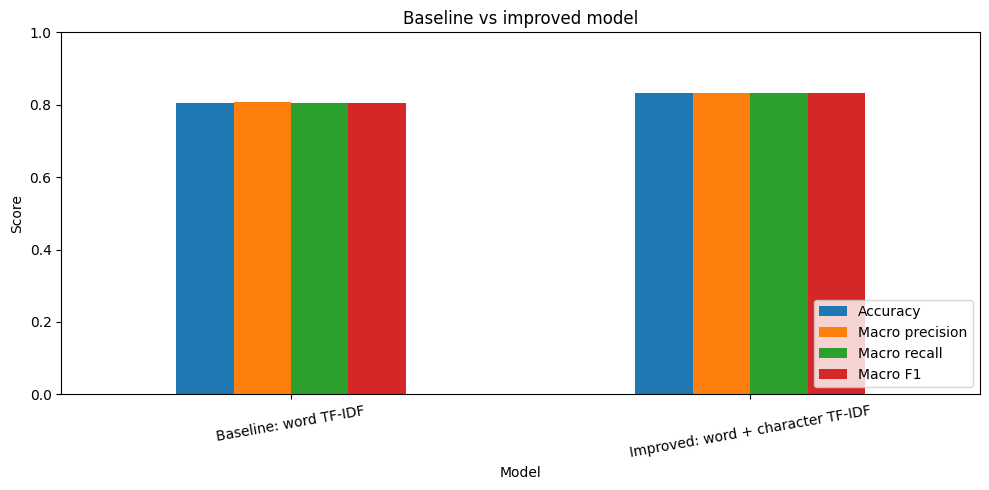

In [10]:
def metric_row(name, y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro precision": p,
        "Macro recall": r,
        "Macro F1": f1
    }

comparison = pd.DataFrame([
    metric_row("Baseline: word TF-IDF", y_test, baseline_predictions),
    metric_row("Improved: word + character TF-IDF", y_test, improved_predictions)
]).set_index("Model")

display(comparison.round(4))
ax = comparison[["Accuracy", "Macro precision", "Macro recall", "Macro F1"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=10
)
ax.set_title("Baseline vs improved model")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10. Error analysis

Accuracy alone does not show which messages are being misclassified. The following table identifies incorrect predictions made by the improved model, including the actual class, predicted class and message text. Pay particular attention to suspicious messages predicted as legitimate and fraudulent messages predicted as legitimate.

In [11]:
error_analysis = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "actual_label": y_test.reset_index(drop=True),
    "predicted_label": pd.Series(improved_predictions)
})
error_analysis = error_analysis[
    error_analysis["actual_label"] != error_analysis["predicted_label"]
].copy()

print("Number of incorrect predictions:", len(error_analysis))
display(error_analysis.head(25))

print("Error counts by actual and predicted class:")
if len(error_analysis):
    display(pd.crosstab(
        error_analysis["actual_label"],
        error_analysis["predicted_label"],
        rownames=["Actual"],
        colnames=["Predicted"]
    ))
else:
    print("No errors in this test split.")

Number of incorrect predictions: 30


,text,actual_label,predicted_label
3,"Title: Junior Presenter for the EUROPEAN OUTDOOR FILM TOUR\nLocation: DE, BY, München\nDepartment: Non-Tech\nCompany Profile: hello worl...",legitimate,suspicious
5,"Title: Entry Level Equities Trader\nLocation: US, ,\nDescription: “Choose a job you love, and you will never have to work a day in your ...",suspicious,legitimate
6,"Title: Summer Internship: Java\nLocation: NZ, ,\nCompany Profile: EROAD was established to modernise New Zealand’s paper-based RUC regim...",suspicious,legitimate
10,"Title: Office Assistant\nLocation: US, NV, Las Vegas\nDescription: What we are looking for:A tenacious, friendly sales representative wh...",suspicious,legitimate
13,"Title: Event Sales Executive\nLocation: GB, ,\nDepartment: Commercial\nCompany Profile: The Beans Group is a media company that exists t...",suspicious,legitimate
21,"Title: JOB VACANCIES AT MONTCALM LUXURY HOTEL LONDON.\nLocation: GB, EAW, London\nSalary Range: 2500-3500\nCompany Profile: Welcome To T...",fraudulent,suspicious
29,Title: Sr. Ruby\nSalary Range: 13000-16000\nDescription: Plated is looking for a full stack ruby on rails engineer to join our team.Plat...,suspicious,legitimate
33,"Title: Development Specialist\nLocation: US, TX, Austin\nDepartment: National Programs\nCompany Profile: Why CSD?CSD is not only a great...",legitimate,suspicious
35,"Title: General Manager for Apparel Startup\nLocation: US, CA, San Francisco\nSalary Range: 30000-48000\nCompany Profile: Innovative stre...",legitimate,suspicious
40,"Title: Data Entry Operator\nLocation: MU, QB,\nDepartment: PECS-DATA\nSalary Range: 104000-120000\nCompany Profile: Hiring made easy for...",legitimate,fraudulent


Error counts by actual and predicted class:


Predicted,fraudulent,legitimate,suspicious
Actual,,,
fraudulent,0,2,3
legitimate,4,0,7
suspicious,3,11,0


## 11. Additional robustness check — duplicate-aware split

A random split can produce optimistic estimates when repeated or very similar examples are present. This additional check groups identical normalised text strings so that exact duplicates cannot cross between training and test sets.

This is a **robustness check**, not a replacement for the primary stratified experiment. Group splitting does not guarantee perfectly balanced class proportions; inspect the printed distributions. Near-duplicate or rule-generated related examples may still cross the split, so this does not eliminate every possible source of leakage.

In [12]:
def normalise_for_grouping(text):
    return re.sub(r"\s+", " ", str(text).lower()).strip()

groups = (data["title"].fillna("").astype(str).map(normalise_for_grouping)
          if "title" in data.columns else X.map(normalise_for_grouping))
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
group_train_idx, group_test_idx = next(gss.split(X, y, groups=groups))

X_group_train = X.iloc[group_train_idx]
X_group_test = X.iloc[group_test_idx]
y_group_train = y.iloc[group_train_idx]
y_group_test = y.iloc[group_test_idx]

print("Group-aware training size:", len(X_group_train))
print("Group-aware test size:", len(X_group_test))
print("\nGroup-aware training class distribution:")
display(y_group_train.value_counts().to_frame("count"))
print("Group-aware test class distribution:")
display(y_group_test.value_counts().to_frame("count"))
print("Grouping uses normalised job title when available; otherwise message text.")
print("Groups shared across train/test:",
      len(set(groups.iloc[group_train_idx]) & set(groups.iloc[group_test_idx])))

group_model = Pipeline([
    ("features", FeatureUnion([
        ("word_tfidf", TfidfVectorizer(
            lowercase=True, stop_words="english", ngram_range=(1, 2),
            max_features=20000, min_df=2, sublinear_tf=True
        )),
        ("char_tfidf", TfidfVectorizer(
            lowercase=True, analyzer="char_wb", ngram_range=(3, 5),
            max_features=20000, min_df=2, sublinear_tf=True
        ))
    ])),
    ("classifier", LogisticRegression(
        max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE
    ))
])

group_model.fit(X_group_train, y_group_train)
group_predictions = group_model.predict(X_group_test)

print("Duplicate-aware split accuracy:",
      round(accuracy_score(y_group_test, group_predictions), 4))
print("\nDuplicate-aware split classification report:")
print(classification_report(y_group_test, group_predictions, zero_division=0))

Group-aware training size: 754
Group-aware test size: 140

Group-aware training class distribution:


,count
label,
suspicious,259
legitimate,249
fraudulent,246


Group-aware test class distribution:


,count
label,
fraudulent,53
legitimate,51
suspicious,36


Grouping uses normalised job title when available; otherwise message text.
Groups shared across train/test: 0
Duplicate-aware split accuracy: 0.8

Duplicate-aware split classification report:
              precision    recall  f1-score   support

  fraudulent       0.81      0.91      0.86        53
  legitimate       0.83      0.75      0.78        51
  suspicious       0.74      0.72      0.73        36

    accuracy                           0.80       140
   macro avg       0.79      0.79      0.79       140
weighted avg       0.80      0.80      0.80       140



## 12. Transparent UAE-relevant warning rules

These rules are deliberately visible and interpretable. They identify warning signs such as recruitment/processing fees, pressure to pay urgently, requests for sensitive information and guaranteed employment. A rule match is a warning sign, not proof that a message is fraudulent.

The guidance is contextualised for UAE job seekers. The prototype does not connect to MOHRE, verify an employer, inspect visa status or contact any government system.

In [13]:
UAE_WARNING_PATTERNS = {
    "Recruitment fee request": [
        r"\brecruitment fee\b",
        r"\bregistration fee\b",
        r"\bprocessing fee\b",
        r"\bvisa processing fee\b",
        r"\bpay (?:today|now|first)\b",
        r"\btransfer money\b",
        r"\bpay.{0,40}(?:visa|job|employment|interview)\b"
    ],
    "Urgent payment pressure": [
        r"\bact immediately\b",
        r"\blimited time offer\b",
        r"\bpay today\b",
        r"\bwithin \d+ hours?\b",
        r"\bimmediate payment\b"
    ],
    "Sensitive information request": [
        r"\bsend (?:your )?passport\b",
        r"\bshare (?:your )?bank details\b",
        r"\bprovide (?:the )?otp\b",
        r"\bone[- ]time password\b",
        r"\bshare (?:your )?password\b"
    ],
    "Guaranteed employment claim": [
        r"\bguaranteed (?:job|employment|visa)\b",
        r"\b100% job guarantee\b"
    ],
    "Unusually attractive earnings": [
        r"\bearn\s+\d{4,}\s*(?:aed|dhs)\b",
        r"\bhigh salary.{0,30}no experience\b",
        r"\bearn immediately\b"
    ]
}

def detect_red_flags(message):
    message = str(message).lower()
    detected = []
    for flag, patterns in UAE_WARNING_PATTERNS.items():
        if any(re.search(pattern, message, flags=re.IGNORECASE) for pattern in patterns):
            detected.append(flag)
    return detected

examples = [
    "Pay a recruitment fee today to guarantee your visa and job.",
    "Please attend the interview on Tuesday. No payment is required.",
    "Send your passport and share your bank details to process the offer.",
    "Earn 15000 AED with no experience. Guaranteed employment."
]

for msg in examples:
    print("Message:", msg)
    print("Potential warning signs:", detect_red_flags(msg) or ["No listed warning sign detected"])
    print("-" * 70)

Message: Pay a recruitment fee today to guarantee your visa and job.
Potential warning signs: ['Recruitment fee request']
----------------------------------------------------------------------
Message: Please attend the interview on Tuesday. No payment is required.
Potential warning signs: ['No listed warning sign detected']
----------------------------------------------------------------------
Message: Send your passport and share your bank details to process the offer.
Potential warning signs: ['Sensitive information request']
----------------------------------------------------------------------
Message: Earn 15000 AED with no experience. Guaranteed employment.
Potential warning signs: ['Guaranteed employment claim', 'Unusually attractive earnings']
----------------------------------------------------------------------


## 13. Prototype prediction function

The output combines the improved model prediction, model score information and transparent warning flags. The highest class score is a model score, not a calibrated probability that a job is genuinely fraudulent. A message with no detected rule is not automatically safe.

In [14]:
def check_job(message):
    message = str(message).strip()
    if not message:
        return {
            "prediction": "Please enter a job-related message.",
            "model_scores": {},
            "warning_flags": [],
            "advice": "Paste the job message or offer text to screen it."
        }

    prediction = improved_model.predict([message])[0]
    scores = improved_model.predict_proba([message])[0]
    class_scores = {
        cls: round(float(score) * 100, 2)
        for cls, score in zip(improved_model.classes_, scores)
    }
    flags = detect_red_flags(message)

    advice = {
        "fraudulent": "High concern: do not pay or share sensitive information. Verify the employer through official channels.",
        "suspicious": "Review carefully: independently verify the employer, job offer and contact details before proceeding.",
        "legitimate": "The model did not identify strong signals in this message. This is not proof that the offer or employer is genuine."
    }[prediction]

    if flags:
        advice += " Warning patterns detected should be checked manually."

    return {
        "prediction": prediction.title(),
        "model_scores": class_scores,
        "warning_flags": flags,
        "advice": advice,
        "disclaimer": "Automated screening only; not an official fraud determination."
    }

demo_messages = [
    "Pay a recruitment fee today to guarantee your visa and job.",
    "We invite you to attend an interview next Tuesday at our office.",
    "Send your passport and bank details immediately to secure your offer."
]
for msg in demo_messages:
    print("INPUT:", msg)
    print(json.dumps(check_job(msg), indent=2))
    print("=" * 80)

INPUT: Pay a recruitment fee today to guarantee your visa and job.
{
  "prediction": "Fraudulent",
  "model_scores": {
    "fraudulent": 35.05,
    "legitimate": 31.93,
    "suspicious": 33.02
  },
  "warning_flags": [
    "Recruitment fee request"
  ],
  "advice": "High concern: do not pay or share sensitive information. Verify the employer through official channels. Warning patterns detected should be checked manually.",
  "disclaimer": "Automated screening only; not an official fraud determination."
}
INPUT: We invite you to attend an interview next Tuesday at our office.
{
  "prediction": "Suspicious",
  "model_scores": {
    "fraudulent": 31.18,
    "legitimate": 25.12,
    "suspicious": 43.71
  },
  "warning_flags": [],
  "advice": "Review carefully: independently verify the employer, job offer and contact details before proceeding.",
  "disclaimer": "Automated screening only; not an official fraud determination."
}
INPUT: Send your passport and bank details immediately to secure

## 14. Save model and experiment outputs

In [15]:
ARTIFACT_DIR = Path("jobshield_artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

joblib.dump(improved_model, ARTIFACT_DIR / "jobshield_tfidf_logistic_regression.joblib")
joblib.dump(baseline_model, ARTIFACT_DIR / "jobshield_baseline_model.joblib")

comparison.to_csv(ARTIFACT_DIR / "model_comparison.csv")
error_analysis.to_csv(ARTIFACT_DIR / "error_analysis.csv", index=False)

experiment_summary = {
    "dataset_id": DATASET_ID,
    "cleaned_dataset_rows": int(len(data)),
    "classes": sorted(y.unique().tolist()),
    "random_state": RANDOM_STATE,
    "primary_test_size": 0.20,
    "baseline_accuracy": float(baseline_accuracy),
    "improved_accuracy": float(improved_accuracy),
    "duplicate_aware_accuracy": float(accuracy_score(y_group_test, group_predictions)),
    "python_note": "Run in Google Colab and record the actual runtime/library versions."
}
with open(ARTIFACT_DIR / "experiment_summary.json", "w") as f:
    json.dump(experiment_summary, f, indent=2)

print("Saved files:")
for p in sorted(ARTIFACT_DIR.iterdir()):
    print(p.name, "-", p.stat().st_size, "bytes")

Saved files:
error_analysis.csv - 77068 bytes
experiment_summary.json - 420 bytes
jobshield_baseline_model.joblib - 1354532 bytes
jobshield_tfidf_logistic_regression.joblib - 2519476 bytes
model_comparison.csv - 260 bytes


## 15. Optional Gradio web demo

Run this cell after the model and warning-rule cells have completed. The public share link generated by Gradio is temporary and may expire when the Colab runtime stops. Do not enter real passport numbers, bank details, OTPs or other private information into a public demo.

In [16]:
import gradio as gr

def gradio_check(message):
    result = check_job(message)
    scores_text = "\\n".join(
        f"{label}: {score}%"
        for label, score in result.get("model_scores", {}).items()
    )
    flags_text = ", ".join(result.get("warning_flags", [])) or "No listed warning pattern detected"
    return (
        result.get("prediction", ""),
        scores_text,
        flags_text,
        result.get("advice", "") + "\\n\\n" + result.get("disclaimer", "")
    )

with gr.Blocks(title="UAE JobShield") as app:
    gr.Markdown("# UAE JobShield — Recruitment Message Screening")
    gr.Markdown(
        "Paste a job advertisement or recruiter message. "
        "This is an experimental screening aid, not an official verification service."
    )
    message_input = gr.Textbox(
        label="Job message",
        lines=6,
        placeholder="Paste the job offer or recruiter message here..."
    )
    check_button = gr.Button("Screen message")
    prediction_output = gr.Textbox(label="Predicted category")
    scores_output = gr.Textbox(label="Model class scores")
    flags_output = gr.Textbox(label="Potential warning signs")
    advice_output = gr.Textbox(label="Suggested next step", lines=4)
    check_button.click(
        fn=gradio_check,
        inputs=message_input,
        outputs=[prediction_output, scores_output, flags_output, advice_output]
    )

# Set share=True to obtain a temporary public URL in Colab.
app.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://65f4b8232ab64d7756.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 16. Export notebook evidence

After the notebook has run successfully, download the executed notebook from Colab using **File → Download → Download .ipynb**. Keep cell outputs. Also download the `jobshield_artifacts` folder from the Colab Files panel if you want to retain the saved model and CSV/JSON experiment outputs.

## 17. Interpretation and limitations to discuss in the report

1. The dataset is small (900 rows before exact-duplicate cleaning) and balanced across three labels; this does not reflect real-world scam prevalence.
2. The dataset is not UAE-specific. UAE relevance comes from the intended use case and transparent warning patterns, not from a UAE-representative training sample.
3. The suspicious class is a dataset-specific category and some examples were synthetically/rule-derived; the model may learn artefacts from how examples were created.
4. TF-IDF captures lexical patterns and does not deeply understand meaning, context, employer identity or intent.
5. Model scores are not calibrated real-world fraud probabilities.
6. Rule-based warnings can miss new scam tactics and can flag legitimate messages that mention fees or personal documents in a different context.
7. The prototype does not verify company licences, job offers, visas or recruiter identities and is not connected to MOHRE.
8. A human should independently verify any offer, especially before paying money or sharing sensitive information.

## 18. References and useful official guidance

- Dataset: https://huggingface.co/datasets/agnialf/Internship-Job-Scam-Dataset
- Original recruitment-fraud dataset research: Vidros, S., Kolias, C., Kambourakis, G., & Akoglu, L. (2017). *Automatic detection of online recruitment frauds: Characteristics, methods, and a public dataset*. Future Internet, 9(1), 6. https://doi.org/10.3390/fi9010006
- UAE Government — Searching for a job: https://u.ae/en/information-and-services/jobs/searching-for-a-job
- UAE Government — Tips to avoid labour and visa fraud: https://u.ae/en/information-and-services/visa-and-emirates-id/tips-to-avoid-labour-and-visa-fraud
- UAE Government — Employment in the private sector: https://u.ae/en/information-and-services/jobs/employment-in-the-private-sector/job-offers-and-work-permits-and-contracts/expatriates-employment-in-private-sector

---
**End of notebook.** Record actual results from your executed run in the report; do not copy expected or previously observed metrics without verifying them.